In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from google.colab import files

# Upload file CSV
uploaded = files.upload()

df = pd.read_csv('dataset_tugas1_preprocessing.csv')
df.head()

Saving dataset_tugas1_preprocessing.csv to dataset_tugas1_preprocessing.csv


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
0,MH001,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,13-04-2020,NaN
1,MH002,Eka,Perempuan,Teknik Komputer,Lulus,E,2020/12/11,28.0
2,MH003,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,2021/11/21,23.0
3,MH004,Eka,Perempuan,Teknik Komputer,Aktif,D,2021/08/19,18.0
4,MH005,Joko,Perempuan,Data Science,Aktif,C,2020/01/05,26.0


In [3]:
# Struktur dan tipe data
df.info()
print("\nUkuran data:", df.shape)

# Jumlah nilai hilang per kolom
print("\nMissing values per kolom:")
print(df.isnull().sum())

# Statistik deskriptif (kolom numerik)
print("\nStatistik deskriptif:")
display(df.describe())

# Statistik deskriptif (kolom kategorikal)
display(df.describe(include='object'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             99 non-null     object 
 1   Nama           99 non-null     object 
 2   Jenis_Kelamin  99 non-null     object 
 3   Prodi          99 non-null     object 
 4   Status         99 non-null     object 
 5   Nilai_Akhir    70 non-null     object 
 6   Tanggal_Ujian  99 non-null     object 
 7   Umur           90 non-null     float64
dtypes: float64(1), object(7)
memory usage: 6.3+ KB

Ukuran data: (99, 8)

Missing values per kolom:
ID                0
Nama              0
Jenis_Kelamin     0
Prodi             0
Status            0
Nilai_Akhir      29
Tanggal_Ujian     0
Umur              9
dtype: int64

Statistik deskriptif:


,Umur
count,90.000000
mean,23.366667
std,3.763963
min,18.000000
25%,20.000000
50%,23.000000
75%,26.000000
max,30.000000


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian
count,99,99,99,99,99,70,99
unique,99,10,2,4,4,5,97
top,MH001,Eka,Laki-laki,Teknik Komputer,Cuti,C,2020/03/31
freq,1,15,50,28,29,17,2


In [4]:
# Umur (numerik) -> median (tahan terhadap outlier)
df['Umur'] = pd.to_numeric(df['Umur'], errors='coerce')
df['Umur'] = df['Umur'].fillna(df['Umur'].median())

# Nilai_Akhir -> median jika numerik, modus jika kategorikal (misal A/B/C)
if pd.api.types.is_numeric_dtype(df['Nilai_Akhir']):
    df['Nilai_Akhir'] = df['Nilai_Akhir'].fillna(df['Nilai_Akhir'].median())
else:
    df['Nilai_Akhir'] = df['Nilai_Akhir'].fillna(df['Nilai_Akhir'].mode()[0])

print(df[['Umur', 'Nilai_Akhir']].isnull().sum())

Umur           0
Nilai_Akhir    0
dtype: int64


In [5]:
df['Tanggal_Ujian'] = pd.to_datetime(
    df['Tanggal_Ujian'], format='mixed', dayfirst=True, errors='coerce'
)

print(df['Tanggal_Ujian'].dtype)                    # harus datetime64[ns]
print("Tanggal gagal terkonversi:", df['Tanggal_Ujian'].isnull().sum())
df['Tanggal_Ujian'].head()

datetime64[ns]
Tanggal gagal terkonversi: 0


,Tanggal_Ujian
0,2020-04-13
1,2020-12-11
2,2021-11-21
3,2021-08-19
4,2020-01-05


In [6]:
# Simpan salinan data sebelum di-encode (dipakai untuk visualisasi)
df_clean = df.copy()

kolom_kategorikal = ['Nama', 'Jenis_Kelamin', 'Prodi', 'Status', 'Nilai_Akhir']

df_encoded = df.copy()
encoders = {}

for col in kolom_kategorikal:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
    encoders[col] = le

df_encoded.head()

,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
0,MH001,8,0,3,0,2,2020-04-13,23.0
1,MH002,4,1,3,3,4,2020-12-11,28.0
2,MH003,8,0,3,0,2,2021-11-21,23.0
3,MH004,4,1,3,0,3,2021-08-19,18.0
4,MH005,9,1,0,0,2,2020-01-05,26.0


In [7]:
train_df, test_df = train_test_split(df_encoded, test_size=0.2, random_state=42)

print("Data latih:", train_df.shape)
print("Data uji  :", test_df.shape)

Data latih: (79, 8)
Data uji  : (20, 8)


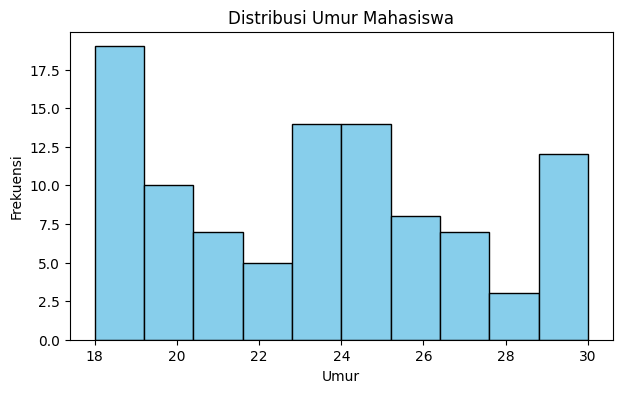

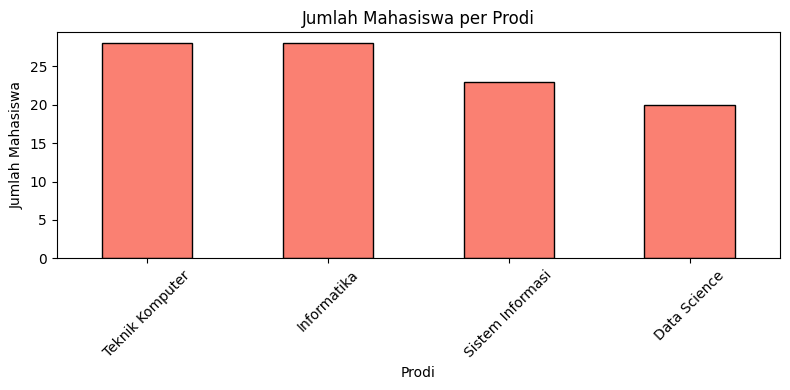

In [10]:
# Histogram Umur
plt.figure(figsize=(7, 4))
plt.hist(df_clean['Umur'], bins=10, color='skyblue', edgecolor='black')
plt.title('Distribusi Umur Mahasiswa')
plt.xlabel('Umur')
plt.ylabel('Frekuensi')
plt.show()

# Grafik batang jumlah mahasiswa per Prodi
plt.figure(figsize=(8, 4))
df_clean['Prodi'].value_counts().plot(kind='bar', color='salmon', edgecolor='black')
plt.title('Jumlah Mahasiswa per Prodi')
plt.xlabel('Prodi')
plt.ylabel('Jumlah Mahasiswa')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()